In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# 1. Load and explore dataset
df = pd.read_csv("retail_sales_dataset.csv")
print(df.head())
print(df.info())


  transaction_id transaction_date customer_id customer_gender  \
0       T0000001       2024-04-24     C000820           Other   
1       T0000002       2025-07-12     C002849           Other   
2       T0000003       2025-06-01     C019727            Male   
3       T0000004       2025-08-26     C009116            Male   
4       T0000005       2024-12-10     C003350            Male   

  customer_age_group customer_segment product_id   product_name  category  \
0              35-44        Returning      P1082      Dumbbells    Sports   
1              45-54              New      P1087  Running Shoes    Sports   
2                55+        Returning      P1030       Sneakers  Clothing   
3              25-34              VIP      P1058      Sunscreen    Beauty   
4              45-54              New      P1028       Sneakers  Clothing   

     brand  quantity  unit_price  discount_pct  sales_amount payment_method  \
0  Brand 1         2      313.53            20        501.65     De

In [7]:
# 2. Group sales by region
region_sales = df.groupby("region")["sales_amount"].sum().sort_values(
    ascending=False
)
print("\nTotal Sales by Region:\n", region_sales)


Total Sales by Region:
 region
Central    9237924.11
West       9106911.70
North      9049438.11
South      8991262.89
East       8971517.64
Name: sales_amount, dtype: float64


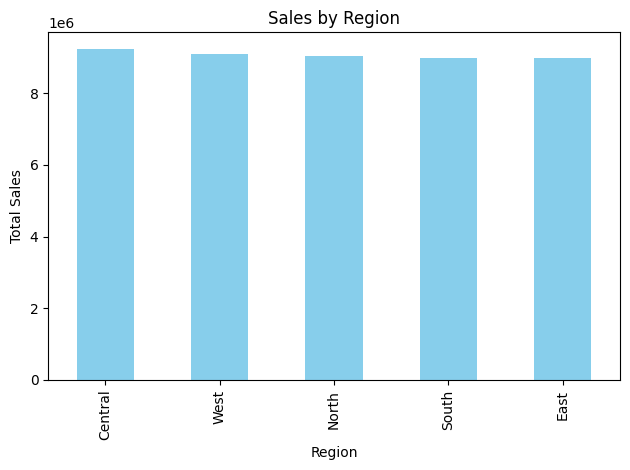

In [9]:
# 3. Bar plot of regional sales
region_sales.plot(kind="bar", color="skyblue")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.title("Sales by Region")
plt.tight_layout()
plt.show()

In [11]:
# 4. Find top-performing regions
print("\nTop Regions:\n", region_sales.head())


Top Regions:
 region
Central    9237924.11
West       9106911.70
North      9049438.11
South      8991262.89
East       8971517.64
Name: sales_amount, dtype: float64


In [15]:
# 5. Group sales by region and product category
sales = df.pivot_table(
    index="region",
    columns="category",
    values="sales_amount",
    aggfunc="sum",
    fill_value=0
)
print("\nSales by Region and Category:\n", sales)


Sales by Region and Category:
 category      Beauty       Books   Clothing  Electronics   Groceries  \
region                                                                 
Central   1347394.43  1209454.66  933664.14   1168890.11  1145513.31   
East      1217359.01  1218160.81  936110.46   1154717.58  1083012.66   
North     1276393.85  1158940.87  925314.94   1209725.50  1059602.66   
South     1261008.81  1236374.24  915517.66   1137434.66  1028547.53   
West      1253562.13  1182307.11  917772.25   1188918.84  1114860.48   

category        Home      Sports        Toys  
region                                        
Central   1102997.19  1197262.64  1132747.63  
East      1113990.63  1131196.06  1116970.43  
North     1165961.60  1156756.30  1096742.39  
South     1138079.99  1174032.61  1100267.39  
West      1134533.39  1204123.15  1110834.35  


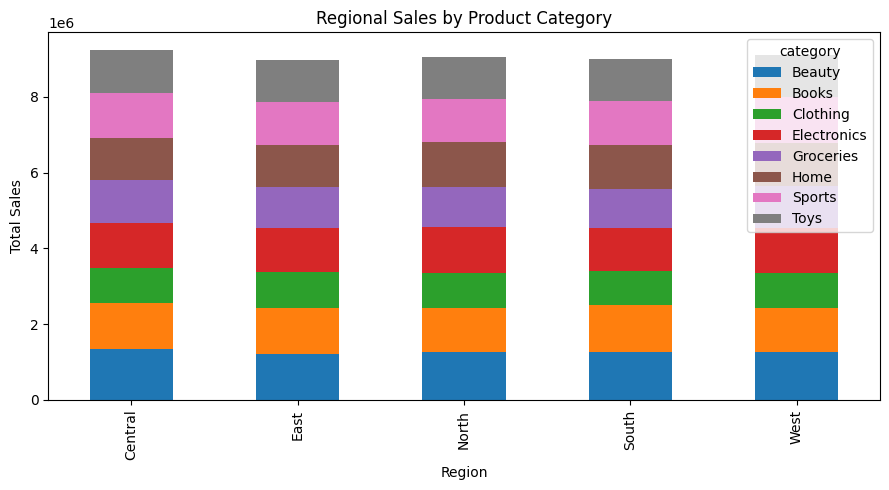

In [17]:
# 6. Stacked bar plot
sales.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.title("Regional Sales by Product Category")
plt.tight_layout()
plt.show()